In [1]:
import os
import glob
import math
from dataclasses import dataclass

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
from scipy.stats import norm
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', '{:.4f}'.format)


In [2]:
class ImageConverter:
    def __init__(self, L_MIN: float = 0.1, L_MAX: float = 300.0):
        self.M = np.array([
            [0.4124564, 0.3575761, 0.1804375],
            [0.2126729, 0.7151522, 0.0721750],
            [0.0193339, 0.1191920, 0.9503041]
        ], dtype=np.float64)
        self.M_inv = np.array([
            [ 3.1338561, -1.6168667, -0.4906146],
            [-0.9787684,  1.9161415,  0.0334540],
            [ 0.0719453, -0.2289914,  1.4052427]
        ], dtype=np.float64)

        self.L_MAX = float(L_MAX)
        self.L_MIN = float(L_MIN)
        self.coord_white = np.array([0.3127, 0.3290, 0.3583], dtype=np.float64)
        self.eps = 1e-10

    def sRGB_Companding(self, linear_image: np.ndarray) -> np.ndarray:
        linear = np.clip(np.asarray(linear_image, dtype=np.float64), 0.0, 1.0)
        encoded = np.where(
            linear <= 0.0031308,
            linear * 12.92,
            1.055 * (linear ** (1.0 / 2.4)) - 0.055
        )
        return encoded

    def Inverse_sRGB_Companding(self, image: np.ndarray) -> np.ndarray:
        img = np.asarray(image, dtype=np.float64)
        linear = np.where(
            img <= 0.04045,
            img / 12.92,
            ((img + 0.055) / 1.055) ** 2.4
        )
        return linear

    def Linear_RGB_to_XYZ(self, image: np.ndarray) -> np.ndarray:
        XYZ_image = image.reshape(-1, 3)
        return (XYZ_image @ self.M.T).reshape(image.shape)

    def XYZ_to_xyzL(self, XYZ_image: np.ndarray) -> np.ndarray:
        sum_xyz = XYZ_image.sum(keepdims=True, axis=-1)
        xyz = XYZ_image / (sum_xyz + self.eps)

        is_black = (sum_xyz < self.eps).squeeze(-1)
        if np.any(is_black):
            xyz[is_black] = self.coord_white

        Y = XYZ_image[..., 1]
        L_norm = np.clip(Y, 0.0, 1.0)
        L_physical = self.L_MIN + L_norm * (self.L_MAX - self.L_MIN)
        L_physical = np.expand_dims(L_physical, axis=-1)

        xyzL = np.concatenate([xyz, L_physical], axis=-1)
        return xyzL

    def RGB_to_xyzL(self, image: np.ndarray) -> np.ndarray:
        norm_img = np.asarray(image, dtype=np.float64) / 255.0
        linRGBimg = self.Inverse_sRGB_Companding(norm_img)
        XYZ_image = self.Linear_RGB_to_XYZ(linRGBimg)
        xyzL_image = self.XYZ_to_xyzL(XYZ_image)
        return xyzL_image

    def L_to_gray(self, L: np.ndarray | float) -> np.ndarray | np.uint8:
        Y_lin = (L - self.L_MIN) / (self.L_MAX - self.L_MIN)
        Y_lin = np.clip(Y_lin, 0.0, 1.0)
        V = self.sRGB_Companding(Y_lin)
        gray_matrix = np.rint(V * 255).astype(np.uint8)
        return gray_matrix

In [3]:
@dataclass(frozen=True)
class AdaptationResult:
    La: float
    loss: float
    success: bool
    iterations: int
    function_evaluations: int
    message: str


def compute_screen_geometry(
    patch_shape: tuple[int, int],
    mode: str,
    distance_m: float = 0.5,
    screen_diag_inch: float = 16.0,
    screen_width_px: int = 1920,
    screen_height_px: int = 1080,
) -> tuple[float, int, int, int]:
    h_patch, w_patch = patch_shape
    n_patch = h_patch * w_patch

    diag_px = math.sqrt(screen_width_px ** 2 + screen_height_px ** 2)
    ppi = diag_px / screen_diag_inch
    pixel_size_m = 0.0254 / ppi
    phi_screen = pixel_size_m / distance_m

    n_total = screen_width_px * screen_height_px

    if mode == 'full':
        return phi_screen, n_patch, n_patch, 0

    if mode == 'orig':
        n_patch_screen = n_patch
        n_bg = max(0, n_total - n_patch_screen)
        return phi_screen, n_total, n_patch_screen, n_bg

    if mode == 'scale_15cm':
        target_size_m = 0.15
        target_max_px = int(np.round((target_size_m / 0.0254) * ppi))
        scale = target_max_px / max(h_patch, w_patch)
        target_w_px = int(np.round(w_patch * scale))
        target_h_px = int(np.round(h_patch * scale))
        n_patch_screen = target_w_px * target_h_px
        n_bg = max(0, n_total - n_patch_screen)
        phi = scale * phi_screen
        return phi, n_total, n_patch_screen, n_bg

    if mode == 'scale_8cm':
        target_size_m = 0.08
        target_max_px = int(np.round((target_size_m / 0.0254) * ppi))
        scale = target_max_px / max(h_patch, w_patch)
        target_w_px = int(np.round(w_patch * scale))
        target_h_px = int(np.round(h_patch * scale))
        n_patch_screen = target_w_px * target_h_px
        n_bg = max(0, n_total - n_patch_screen)
        phi = scale * phi_screen
        return phi, n_total, n_patch_screen, n_bg

    if mode == 'scale_50pct':
        n_patch_screen = n_total // 2
        n_bg = n_total - n_patch_screen
        scale = math.sqrt(n_patch_screen / n_patch)
        phi = scale * phi_screen
        return phi, n_total, n_patch_screen, n_bg

    raise ValueError(f"Неизвестный режим: {mode}")


class HistogramAdaptationJNDModel:
    def __init__(
        self,
        *,
        exposure_time: float = 1.0,
        angular_size_rad: float = 1e-3,
        detection_probability: float = 0.75,
        absolute_threshold: float = 1e-6,
        luminance_floor: float = 1e-6,
        l_min: float = 0.1,
        l_max: float = 300.0,
        screen_width_px: int = 1920,
        screen_height_px: int = 1080,
        l_gray: float = 60.0
    ) -> None:
        self.t = float(exposure_time)
        self.phi_d = float(angular_size_rad)
        self.p = float(detection_probability)
        self.L0 = float(absolute_threshold)
        self.luminance_floor = float(luminance_floor)

        self.l_min = float(l_min)
        self.l_max = float(l_max)
        self.screen_width_px = int(screen_width_px)
        self.screen_height_px = int(screen_height_px)
        self.l_gray = float(l_gray)

        self.la = self.l_gray
        self.bounds = np.empty(0, dtype=np.float64)
        self.len_left = 0

    @staticmethod
    def _K(lambd, b1=0.98, b2=0.1, lambd1=2e-2):
        lambd = np.asarray(lambd, dtype=np.float64)
        return np.where(lambd <= 1.0, b1 * (1.0 + lambd1 / lambd), lambd**b2)

    @staticmethod
    def _A(La, a1=4.8e6, a2=7.1e3, a3=4.5e-4):
        return 1.0 + np.sqrt(a1 * La) + a2 * La * (1.0 + np.sqrt(a3 * La))

    def _Lambda(self, lambd):
        return lambd * self._K(lambd)

    @staticmethod
    def _eta(La, L3=1e6, L4=1.0, a4=600.0):
        return 1.0 + L3 / (1.0 + a4 * La * (L4 + La))

    def _C(self, La):
        tau_min = 0.05
        T = self.t / (tau_min * self._eta(La))
        return 1.0 + 1.0 / T

    @staticmethod
    def _func_phi_1(La, c2=0.25, L1=10.0, L2=2.6e-5):
        return (1.0 + L1 / (L2 + La)) ** c2

    def _S(self, La, theta_1=6.1, a_d=2.0, inf_phi_1=1.0):
        phi_0_min = 0.5 * (1.0 / 60.0) * (np.pi / 180.0)
        phi_0 = self._func_phi_1(La) * phi_0_min / inf_phi_1
        return (theta_1 * phi_0 / self.phi_d + 1.0) ** a_d

    def _l(self, La):
        return self.L0 * self._A(La)

    def _P(self, p_ref=0.75):
        return abs(norm.ppf(self.p) / norm.ppf(p_ref))

    def D(self, L, La):
        L = np.maximum(np.asarray(L, dtype=np.float64), self.luminance_floor)
        La = np.maximum(np.asarray(La, dtype=np.float64), self.luminance_floor)
        lambd = L / (1e2 * self._l(La))
        return self.L0 * self._A(La) * self._C(La) * self._Lambda(lambd) * self._S(La) * self._P()

    def prepare_histogram(self, luminance, probability) -> tuple[np.ndarray, np.ndarray]:
        L = np.asarray(luminance, dtype=np.float64).reshape(-1)
        p = np.asarray(probability, dtype=np.float64).reshape(-1)

        L = np.maximum(L, self.luminance_floor)
        keep = p > 0
        L, p = L[keep], p[keep]

        unique_L, inverse = np.unique(L, return_inverse=True)
        merged_p = np.zeros(unique_L.size, dtype=np.float64)
        np.add.at(merged_p, inverse, p)
        merged_p /= merged_p.sum()
        return unique_L, merged_p

    def extract_image_histogram(
        self,
        patch: np.ndarray,
        n_total: int,
        n_patch_screen: int,
        n_bg: int,
        l_bg: float | None = None
    ) -> tuple[np.ndarray, np.ndarray]:
        flat = np.asarray(patch, dtype=np.float64).ravel()
        bg_lum = self.l_gray if l_bg is None else float(l_bg)

        unique_L, counts = np.unique(flat, return_counts=True)
        probs = (counts / flat.size) * (n_patch_screen / n_total)

        if n_bg > 0:
            unique_L = np.append(unique_L, bg_lum)
            probs = np.append(probs, n_bg / n_total)

        return self.prepare_histogram(unique_L, probs)

    def loss(self, La: float, luminance, probability) -> float:
        if not np.isfinite(La) or La <= 0:
            return math.inf
        L, p = self.prepare_histogram(luminance, probability)
        ratio = self.D(L, La) / self.D(La, L)
        if np.any(~np.isfinite(ratio)) or np.any(ratio <= 0):
            return math.inf
        return float(np.sum(p * np.abs(np.log(ratio))))

    def fit(self, luminance, probability, bounds: tuple[float, float] | None = None, xatol: float = 1e-6) -> AdaptationResult:
        L, p = self.prepare_histogram(luminance, probability)
        if bounds is None and L.size == 1:
            center = float(L[0])
            lower, upper = max(center / 100.0, self.luminance_floor), center * 100.0
        else:
            lower, upper = bounds if bounds is not None else (float(L.min()), float(L.max()))
        lower = max(float(lower), self.luminance_floor)
        upper = float(upper)
        if lower >= upper:
            lower = max(lower / 2.0, self.luminance_floor)
            upper = upper * 2.0

        def objective(log_La):
            La = math.exp(float(log_La))
            ratio = self.D(L, La) / self.D(La, L)
            return float(np.sum(p * np.abs(np.log(ratio))))

        opt = minimize_scalar(
            objective,
            bounds=(math.log(lower), math.log(upper)),
            method="bounded",
            options={"xatol": float(xatol)},
        )
        La = math.exp(float(opt.x))
        return AdaptationResult(
            La=La,
            loss=float(opt.fun),
            success=bool(opt.success),
            iterations=int(opt.nit),
            function_evaluations=int(opt.nfev),
            message=str(opt.message),
        )

    def find_la(self, patch: np.ndarray, n_total: int, n_patch_screen: int, n_bg: int, l_bg: float | None = None) -> float:
        L, p = self.extract_image_histogram(patch, n_total, n_patch_screen, n_bg, l_bg)
        res = self.fit(L, p)
        self.la = res.La
        return self.la

    def build_level_boundaries(self) -> np.ndarray:
        right_bounds: list[float] = []
        curr_l = self.la
        while curr_l < self.l_max:
            step = float(self.D(L=curr_l, La=self.la))
            if step <= 0:
                break
            curr_l += step
            right_bounds.append(min(curr_l, self.l_max))

        left_bounds: list[float] = []
        curr_l = self.la
        while curr_l > self.L0:
            step = float(self.D(L=curr_l, La=self.la))
            if step <= 0:
                break
            curr_l -= step
            left_bounds.append(max(curr_l, self.L0))

        self.len_left = len(left_bounds)
        left_bounds.reverse()
        self.bounds = np.array(left_bounds + [self.la] + right_bounds, dtype=np.float64)
        return self.bounds

    def l_to_k(self, l_val: float | np.ndarray) -> int | np.ndarray:
        idx = np.searchsorted(self.bounds, l_val, side="right") - 1
        idx = np.clip(idx, 0, len(self.bounds) - 1)
        return idx - self.len_left


In [4]:
def compute_jnd_step_metrics(
    l_matrix: np.ndarray,
    bounds: np.ndarray,
    converter: ImageConverter,
    l_bg: float | None = None,
    has_bg: bool = False
) -> dict:
    idx = np.searchsorted(bounds, l_matrix, side='right') - 1
    idx = np.clip(idx, 0, len(bounds) - 2)

    lower_L = bounds[idx]
    upper_L = bounds[idx + 1]

    def to_pixel_scale(L_arr):
        y_lin = np.clip((L_arr - converter.L_MIN) / (converter.L_MAX - converter.L_MIN), 0.0, 1.0)
        return converter.sRGB_Companding(y_lin) * 255.0

    pixel_val = to_pixel_scale(l_matrix)
    lower_px = to_pixel_scale(lower_L)
    upper_px = to_pixel_scale(upper_L)

    delta_down_px = pixel_val - lower_px
    delta_up_px = upper_px - pixel_val
    delta_px = np.minimum(delta_down_px, delta_up_px)
    delta_px = np.maximum(delta_px, 0.0)

    jnd_steps_px = upper_px - lower_px

    img_l_min = float(np.min(l_matrix))
    img_l_max = float(np.max(l_matrix))
    if has_bg and l_bg is not None:
        scene_l_min = min(img_l_min, float(l_bg))
        scene_l_max = max(img_l_max, float(l_bg))
    else:
        scene_l_min = img_l_min
        scene_l_max = img_l_max

    idx_min = int(np.searchsorted(bounds, scene_l_min, side='right') - 1)
    idx_max = int(np.searchsorted(bounds, scene_l_max, side='right') - 1)
    idx_min = max(0, min(idx_min, len(bounds) - 2))
    idx_max = max(0, min(idx_max, len(bounds) - 2))
    num_levels = max(1, idx_max - idx_min + 1)

    delta_flat = delta_px.ravel()
    steps_flat = jnd_steps_px.ravel()

    return {
        "num_levels": num_levels,
        "min_delta_to_level_change": float(np.min(delta_flat)),
        "min_jnd_step": float(np.min(steps_flat)),
        "mean_delta_L1": float(np.mean(delta_flat)),
        "mean_jnd_step": float(np.mean(steps_flat))
    }

## Блок 1. Влияние режима экрана и наличия фона

### Что тестируем
Пять режимов размещения изображения на дисплее:
1. `full`: фото занимает 100% экрана, фона нет.
2. `scale_50pct`: фото занимает 50% площади экрана, 50% занимает фон.
3. `scale_15cm`: фото отмасштабировано до 15 см по длинной стороне.
4. `scale_8cm`: фото отмасштабировано до 8 см по длинной стороне.
5. `orig`: фото в исходном масштабе 1:1 по центру экрана, остальное залито фоном.

### Что проверяем
Как появление и рост доли фонового поля смещают адаптацию La, число различимых уровней (num_levels) и средний допустимый сдвиг пикселя (mean_delta_L1) для 5 изображений.

### Параметры эксперимента
* Режимы отображения: `full`, `scale_50pct`, `scale_15cm`, `scale_8cm`, `orig`
* Экран: диагональ 16 дюймов, разрешение 1920x1080
* Расстояние до экрана: 0.5 м
* Яркость фона L_bg: 60.0 кд/м² (для режимов с фоном)

### Описание колонок таблицы (в единицах RGB от 0 до 255)
* **num_levels**: число ступеней JND в диапазоне яркостей сцены (с учетом фона при его наличии).
* **min_delta_to_level_change**: минимальный сдвиг пикселя в RGB, достаточный для смены JND-уровня (из-за непрерывности яркостей близко к 0).
* **min_jnd_step**: минимальная ширина ступени квантования (минимальный Simkin score).
* **mean_delta_L1**: средний допустимый сдвиг пикселя в RGB (от 0 до 255). Это не яркость пикселя, а расстояние до границы уровня: на сколько в среднем можно изменить значение пикселя, не меняя его восприятия глазом.
* **mean_jnd_step**: средняя ширина ступени квантования JND в значениях RGB.

,image,mean_L_img,mode,La,num_levels,min_delta_to_level_change,min_jnd_step,mean_delta_L1,mean_jnd_step
0,1.jpg,108.7321,full,106.4952,40,0.0000,0.5578,2.2130,8.8834
1,1.jpg,108.7321,scale_50pct,60.0000,127,0.0000,0.1881,0.7985,3.1932
2,1.jpg,108.7321,scale_15cm,60.0000,60,0.0000,0.4232,1.6491,6.5940
3,1.jpg,108.7321,scale_8cm,60.0000,24,0.0000,2.8036,3.9242,15.5740
4,1.jpg,108.7321,orig,60.0000,42,0.0000,0.0655,2.3272,9.3563
5,2.jpg,21.4713,full,9.2819,23,0.0000,0.8134,2.3945,9.5907
6,2.jpg,21.4713,scale_50pct,60.0000,109,0.0000,0.0017,0.4464,1.7915
7,2.jpg,21.4713,scale_15cm,60.0000,59,0.0000,0.0936,0.8427,3.3719
8,2.jpg,21.4713,scale_8cm,60.0000,24,0.0000,0.6510,2.2277,8.8789
9,2.jpg,21.4713,orig,60.0000,41,0.0000,1.7385,1.1896,4.7502


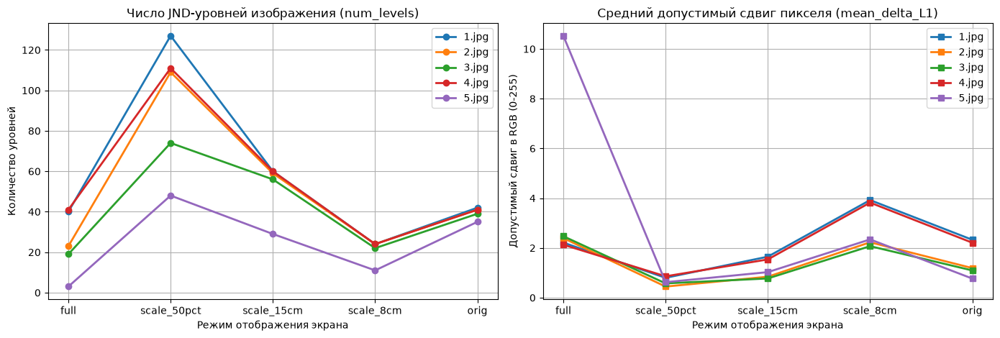

In [5]:
image_paths = [f'examples/{i}.jpg' for i in range(1, 6)]
if not os.path.exists(image_paths[0]):
    image_paths = [f'../examples/{i}.jpg' for i in range(1, 6)]

converter = ImageConverter(L_MIN=0.1, L_MAX=300.0)
display_modes = ['full', 'scale_50pct', 'scale_15cm', 'scale_8cm', 'orig']
exp1_results = []

for img_path in image_paths:
    img_bgr = cv2.imread(img_path)
    if img_bgr is None:
        continue
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    l_physical = converter.RGB_to_xyzL(img_rgb)[..., 3]
    mean_L = float(np.mean(l_physical))
    img_name = os.path.basename(img_path)

    for mode in display_modes:
        phi, n_total, n_patch_screen, n_bg = compute_screen_geometry(
            patch_shape=l_physical.shape,
            mode=mode,
            distance_m=0.5
        )

        model = HistogramAdaptationJNDModel(
            angular_size_rad=phi,
            l_gray=60.0
        )

        la = model.find_la(l_physical, n_total, n_patch_screen, n_bg, l_bg=60.0)
        bounds = model.build_level_boundaries()
        metrics = compute_jnd_step_metrics(
            l_physical, bounds, converter, l_bg=60.0, has_bg=(n_bg > 0)
        )

        exp1_results.append({
            "image": img_name,
            "mean_L_img": mean_L,
            "mode": mode,
            "La": la,
            **metrics
        })

df_exp1 = pd.DataFrame(exp1_results)
display(df_exp1[["image", "mean_L_img", "mode", "La", "num_levels", "min_delta_to_level_change", "min_jnd_step", "mean_delta_L1", "mean_jnd_step"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

for img_name in df_exp1['image'].unique():
    sub = df_exp1[df_exp1['image'] == img_name]
    axes[0].plot(sub['mode'], sub['num_levels'], marker='o', linewidth=2, label=img_name)
    axes[1].plot(sub['mode'], sub['mean_delta_L1'], marker='s', linewidth=2, label=img_name)

axes[0].set_title("Число JND-уровней изображения (num_levels)")
axes[0].set_xlabel("Режим отображения экрана")
axes[0].set_ylabel("Количество уровней")
axes[0].grid(True)
axes[0].legend()

axes[1].set_title("Средний допустимый сдвиг пикселя (mean_delta_L1)")
axes[1].set_xlabel("Режим отображения экрана")
axes[1].set_ylabel("Допустимый сдвиг в RGB (0-255)")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


## Блок 2. Влияние яркости фонового пространства (L_bg: от 5 до 250 кд/м2)

### Что тестируем
Изменение яркости фона экрана L_bg от 5 до 250 кд/м² при исходном размере изображения (режим `orig`).

### Что проверяем
В режиме `orig` фон занимает от 85% до 96% всей площади монитора 1920x1080. Из-за этого дельта-пик фона полностью доминирует в поле зрения и строго привязывает зрительную адаптацию к себе (La = L_bg). Мы проверяем, как при такой фоновой адаптации меняется восприятие самой картинки (средний допустимый сдвиг пикселей mean_delta_L1).

### Параметры эксперимента
* Режим отображения: `orig` (оригинал 1:1 в центре экрана, фон занимает 85-96% площади)
* Значения яркости фона L_bg: от 5 до 250 кд/м²
* Экран: диагональ 16 дюймов, разрешение 1920x1080
* Расстояние до экрана: 0.5 м

,image,mean_L_img,L_bg,La,num_levels,min_delta_to_level_change,min_jnd_step,mean_delta_L1,mean_jnd_step
0,1.jpg,108.7321,5.0000,5.0000,11,0.0000,0.2666,10.7379,43.2149
1,1.jpg,108.7321,15.0000,15.0000,33,0.0000,0.7461,3.6347,14.4755
2,1.jpg,108.7321,30.0000,30.0000,42,0.0000,0.3667,2.6711,10.7785
3,1.jpg,108.7321,60.0000,60.0000,42,0.0000,0.0655,2.3272,9.3563
4,1.jpg,108.7321,100.0000,100.0000,40,0.0000,0.2868,2.2292,8.8931
5,1.jpg,108.7321,150.0000,150.0000,37,0.0000,2.1098,2.2292,8.9339
6,1.jpg,108.7321,200.0000,200.0000,35,0.0000,3.4110,2.2821,9.1481
7,1.jpg,108.7321,250.0000,250.0000,33,0.0000,4.2775,2.3376,9.3618
8,2.jpg,21.4713,5.0000,5.0000,11,0.0000,0.2666,5.0979,20.5629
9,2.jpg,21.4713,15.0000,15.0000,33,0.0000,0.7461,1.6290,6.5388


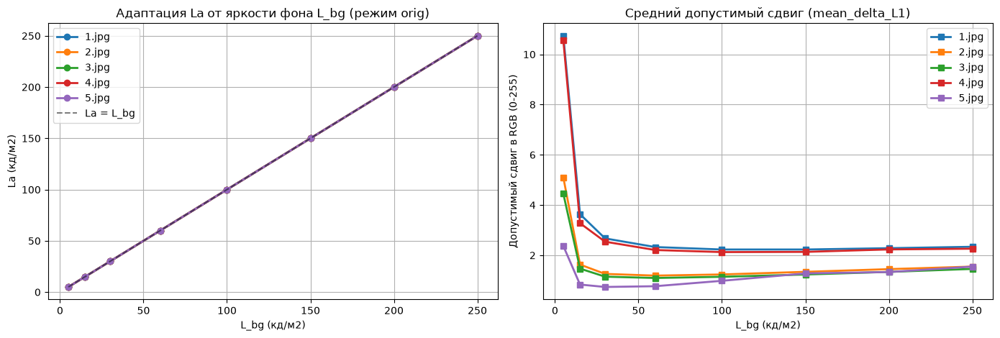

In [6]:
bg_luminances = [5.0, 15.0, 30.0, 60.0, 100.0, 150.0, 200.0, 250.0]
exp2_results = []

for img_path in image_paths:
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    l_physical = converter.RGB_to_xyzL(img_rgb)[..., 3]
    img_name = os.path.basename(img_path)
    mean_L = float(np.mean(l_physical))

    phi, n_total, n_patch_screen, n_bg = compute_screen_geometry(
        patch_shape=l_physical.shape,
        mode='orig',
        distance_m=0.5
    )

    for bg_l in bg_luminances:
        model = HistogramAdaptationJNDModel(
            angular_size_rad=phi,
            l_gray=bg_l
        )

        la = model.find_la(l_physical, n_total, n_patch_screen, n_bg, l_bg=bg_l)
        bounds = model.build_level_boundaries()
        metrics = compute_jnd_step_metrics(
            l_physical, bounds, converter, l_bg=bg_l, has_bg=True
        )

        exp2_results.append({
            "image": img_name,
            "mean_L_img": mean_L,
            "L_bg": bg_l,
            "La": la,
            **metrics
        })

df_exp2 = pd.DataFrame(exp2_results)
display(df_exp2[["image", "mean_L_img", "L_bg", "La", "num_levels", "min_delta_to_level_change", "min_jnd_step", "mean_delta_L1", "mean_jnd_step"]].head(20))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for img_name in df_exp2['image'].unique():
    sub = df_exp2[df_exp2['image'] == img_name]
    axes[0].plot(sub['L_bg'], sub['La'], marker='o', linewidth=2, label=img_name)
    axes[1].plot(sub['L_bg'], sub['mean_delta_L1'], marker='s', linewidth=2, label=img_name)

axes[0].plot(bg_luminances, bg_luminances, 'k--', alpha=0.5, label='La = L_bg')
axes[0].set_title("Адаптация La от яркости фона L_bg (режим orig)")
axes[0].set_xlabel("L_bg (кд/м2)")
axes[0].set_ylabel("La (кд/м2)")
axes[0].grid(True)
axes[0].legend()

axes[1].set_title("Средний допустимый сдвиг (mean_delta_L1)")
axes[1].set_xlabel("L_bg (кд/м2)")
axes[1].set_ylabel("Допустимый сдвиг в RGB (0-255)")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


## Блок 3. Влияние расстояния наблюдения (d: от 0.3 до 1.5 м)

### Что тестируем
Удаление наблюдателя от экрана от 30 см до 1.5 м в режиме `full` (без фона).

### Что проверяем
Падение числа различимых уровней и рост допустимого сдвига пикселей при удалении от монитора (эффект уменьшения видимого размера пикселя для глаза).

### Параметры эксперимента
* Режим отображения: `full` (изображение на весь экран, фона нет)
* Значения расстояния d: от 0.3 до 1.5 м
* Экран: диагональ 16 дюймов, разрешение 1920x1080

,image,distance_m,La,num_levels,min_delta_to_level_change,min_jnd_step,mean_delta_L1,mean_jnd_step
0,1.jpg,0.3000,106.5062,77,0.0000,1.3711,1.1453,4.5881
1,1.jpg,0.4000,106.4963,54,0.0000,0.0112,1.6484,6.5993
2,1.jpg,0.5000,106.4952,40,0.0000,0.5578,2.2130,8.8834
3,1.jpg,0.7000,106.4761,24,0.0000,2.4126,3.6042,14.5479
4,1.jpg,1.0000,106.4734,13,0.0000,6.0041,6.5363,25.9569
5,1.jpg,1.5000,106.4734,6,0.0000,1.3819,14.4223,57.2126
6,2.jpg,0.3000,9.2815,46,0.0000,0.3694,1.2151,4.8543
7,2.jpg,0.4000,9.2815,32,0.0000,0.4252,1.7556,7.0288
8,2.jpg,0.5000,9.2819,23,0.0000,0.8134,2.3945,9.5907
9,2.jpg,0.7000,9.2815,14,0.0000,1.1062,4.0416,16.0794


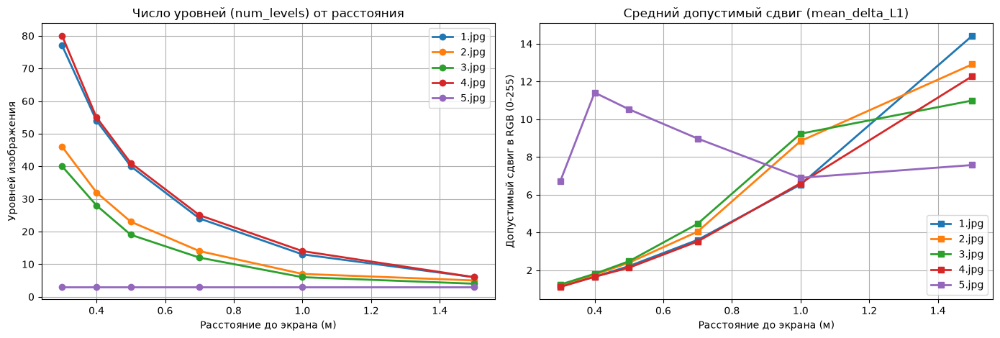

In [7]:
distances = [0.3, 0.4, 0.5, 0.7, 1.0, 1.5]
exp3_results = []

for img_path in image_paths:
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    l_physical = converter.RGB_to_xyzL(img_rgb)[..., 3]
    img_name = os.path.basename(img_path)

    for dist in distances:
        phi, n_total, n_patch_screen, n_bg = compute_screen_geometry(
            patch_shape=l_physical.shape,
            mode='full',
            distance_m=dist
        )

        model = HistogramAdaptationJNDModel(
            angular_size_rad=phi,
            l_gray=60.0
        )

        la = model.find_la(l_physical, n_total, n_patch_screen, n_bg)
        bounds = model.build_level_boundaries()
        metrics = compute_jnd_step_metrics(
            l_physical, bounds, converter, has_bg=False
        )

        exp3_results.append({
            "image": img_name,
            "distance_m": dist,
            "La": la,
            **metrics
        })

df_exp3 = pd.DataFrame(exp3_results)
display(df_exp3[["image", "distance_m", "La", "num_levels", "min_delta_to_level_change", "min_jnd_step", "mean_delta_L1", "mean_jnd_step"]])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for img_name in df_exp3['image'].unique():
    sub = df_exp3[df_exp3['image'] == img_name]
    axes[0].plot(sub['distance_m'], sub['num_levels'], marker='o', linewidth=2, label=img_name)
    axes[1].plot(sub['distance_m'], sub['mean_delta_L1'], marker='s', linewidth=2, label=img_name)

axes[0].set_title("Число уровней (num_levels) от расстояния")
axes[0].set_xlabel("Расстояние до экрана (м)")
axes[0].set_ylabel("Уровней изображения")
axes[0].grid(True)
axes[0].legend()

axes[1].set_title("Средний допустимый сдвиг (mean_delta_L1)")
axes[1].set_xlabel("Расстояние до экрана (м)")
axes[1].set_ylabel("Допустимый сдвиг в RGB (0-255)")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.show()


## Блок 4. Пространственный анализ и кривые уязвимости для 5 изображений во всех режимах

### Что тестируем
Попиксельный анализ запаса до границы JND для каждого из пяти изображений во всех пяти режимах экрана (`full`, `scale_50pct`, `scale_15cm`, `scale_8cm`, `orig`).

### Что проверяем
Для каждого изображения выводится отдельный блок из 5 строк (по одной на каждый режим экрана) и 3 колонок:
1. Исходное фото.
2. Пространственная тепловая карта запаса до границы JND в единицах RGB.
3. Кумулятивная кривая уязвимости бюджета (CDF): процент пикселей, меняющих уровень при допустимом сдвиге eps в RGB.

### Параметры эксперимента
* Исследуемые режимы: `full`, `scale_50pct`, `scale_15cm`, `scale_8cm`, `orig`
* Экран: диагональ 16 дюймов, разрешение 1920x1080
* Расстояние до экрана: 0.5 м
* Яркость фона L_bg: 60.0 кд/м² (для режимов с фоном)

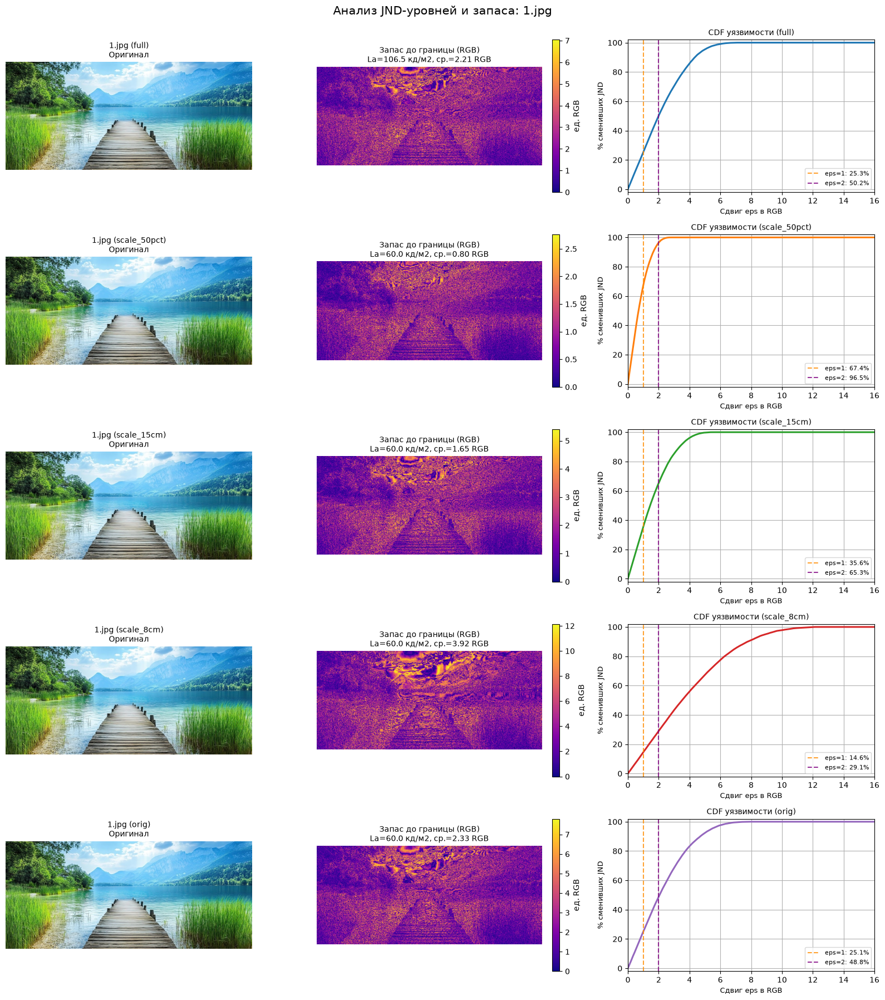

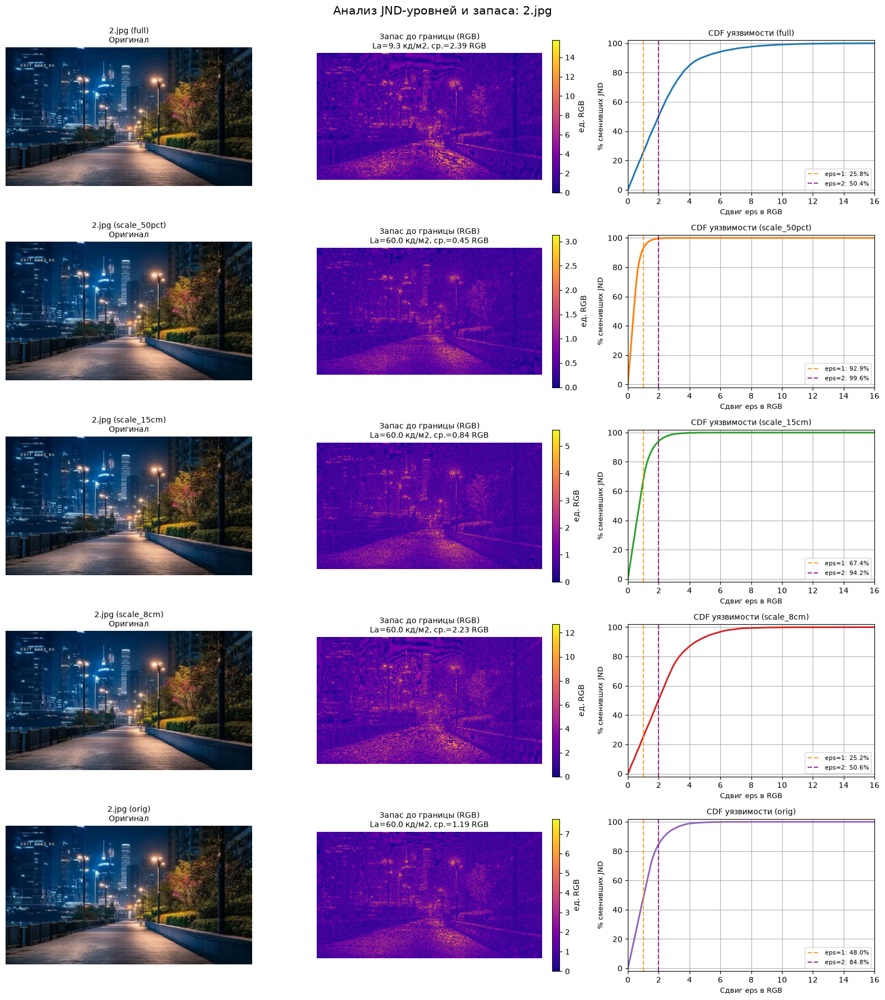

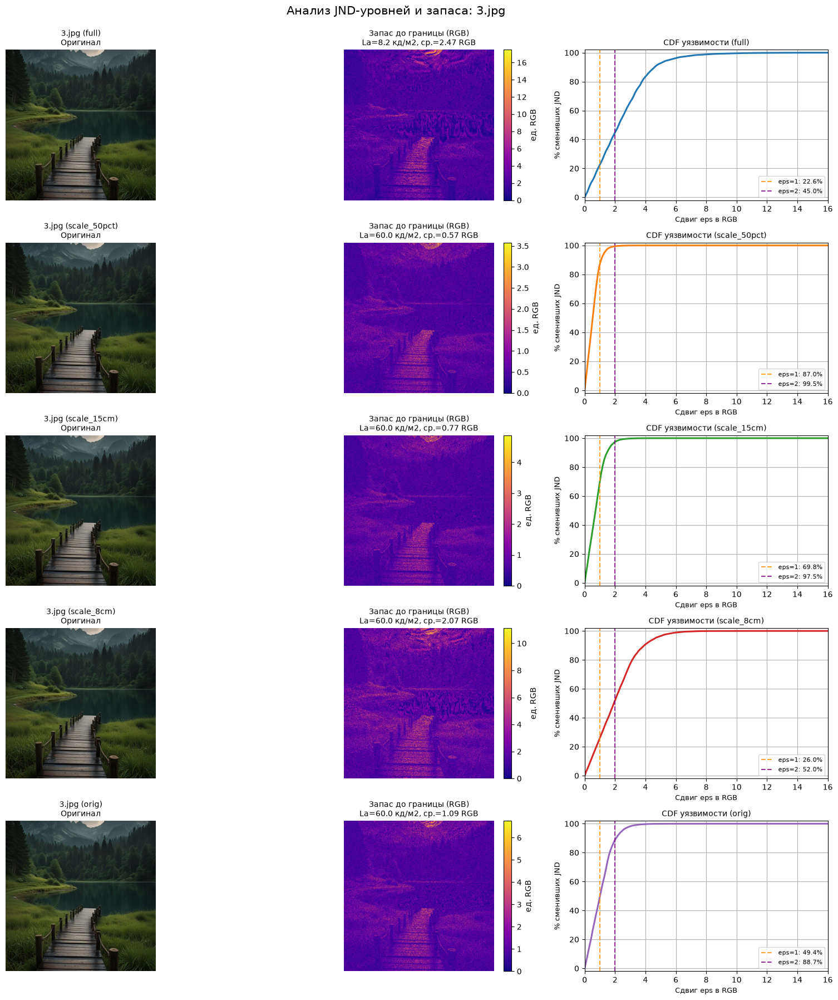

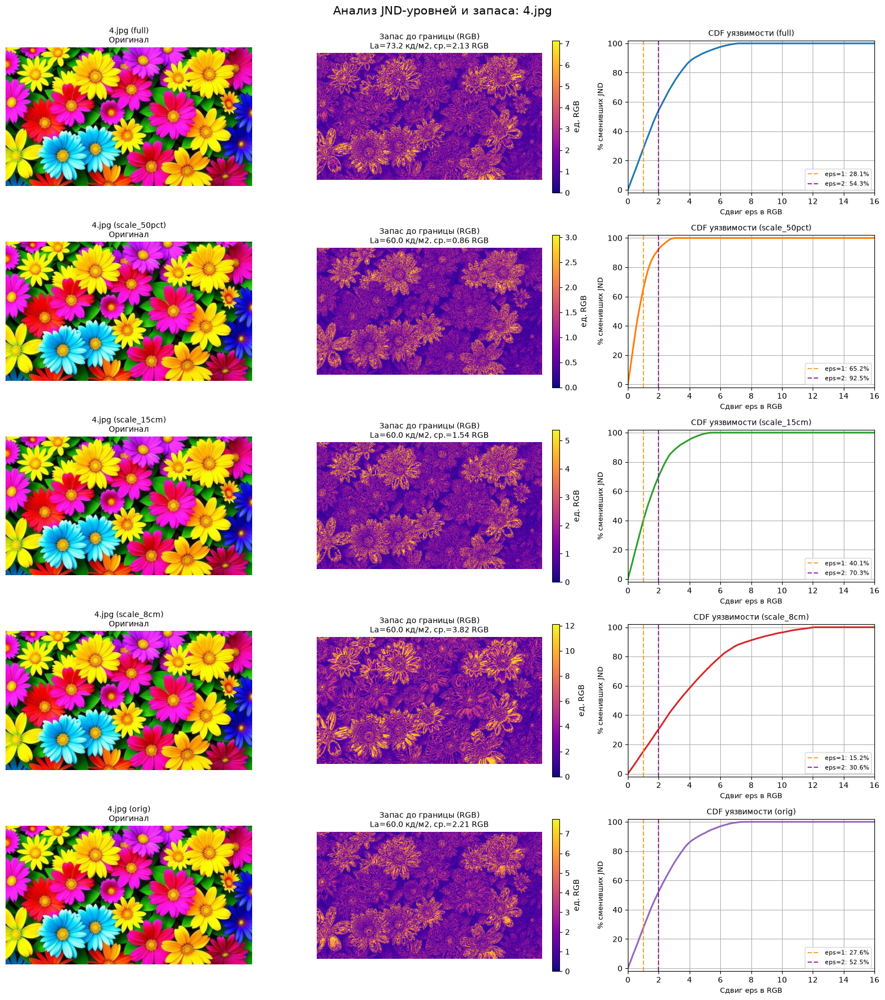

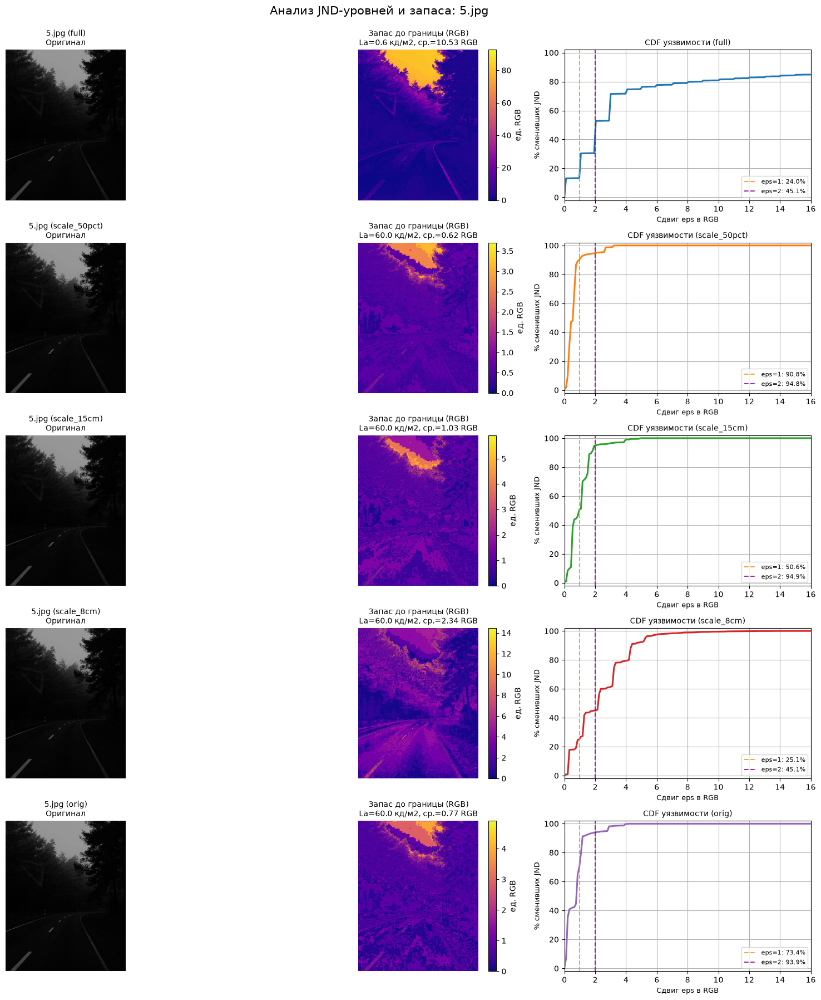

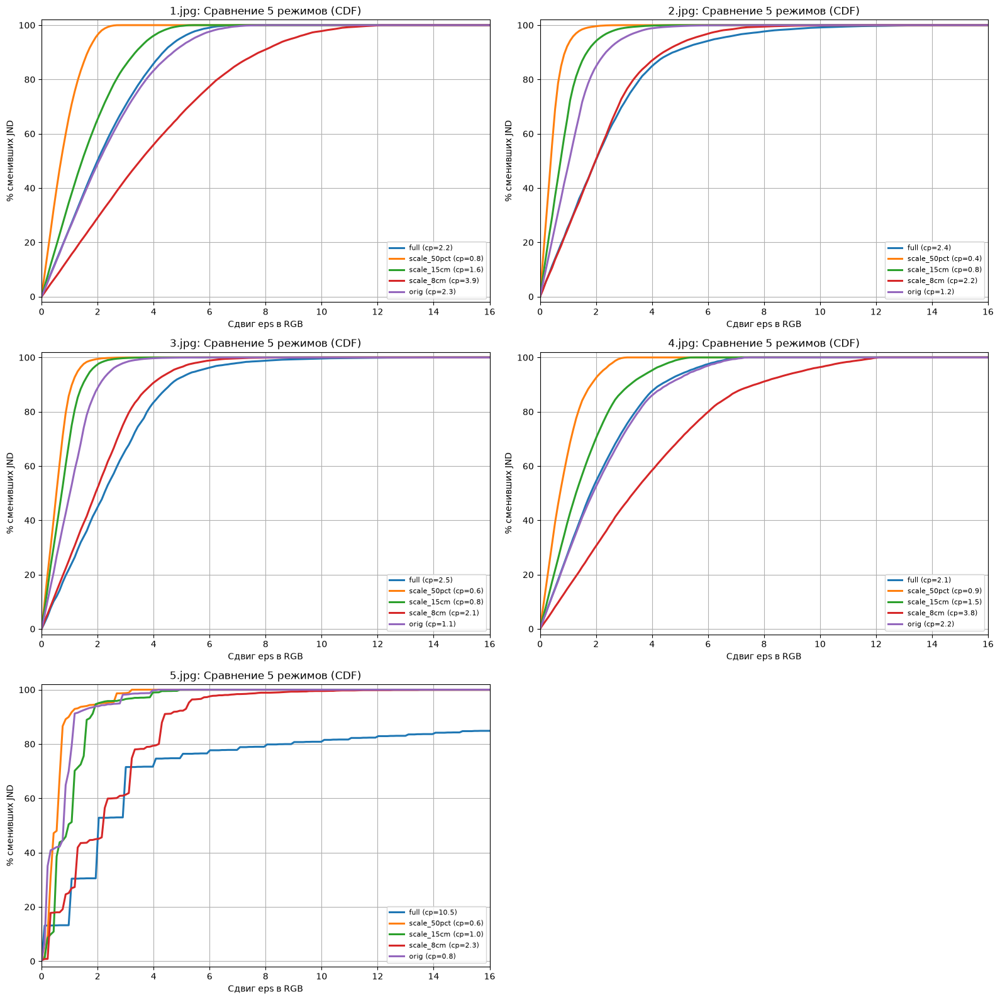

In [8]:
modes = ['full', 'scale_50pct', 'scale_15cm', 'scale_8cm', 'orig']
mode_colors = {
    'full': '#1f77b4',
    'scale_50pct': '#ff7f0e',
    'scale_15cm': '#2ca02c',
    'scale_8cm': '#d62728',
    'orig': '#9467bd'
}

def to_pixel_scale(L_arr):
    y_lin = np.clip((L_arr - converter.L_MIN) / (converter.L_MAX - converter.L_MIN), 0.0, 1.0)
    return converter.sRGB_Companding(y_lin) * 255.0

def to_phys_scale(px_arr):
    y_lin = converter.Inverse_sRGB_Companding(np.clip(px_arr / 255.0, 0.0, 1.0))
    return converter.L_MIN + y_lin * (converter.L_MAX - converter.L_MIN)

for img_path in image_paths:
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    l_physical = converter.RGB_to_xyzL(img_rgb)[..., 3]
    pixel_val = to_pixel_scale(l_physical)
    img_name = os.path.basename(img_path)

    fig, axes = plt.subplots(5, 3, figsize=(16, 18))
    fig.suptitle(f"Анализ JND-уровней и запаса: {img_name}", fontsize=15, y=0.995)

    for row_idx, mode in enumerate(modes):
        phi, n_total, n_patch_screen, n_bg = compute_screen_geometry(
            l_physical.shape, mode=mode, distance_m=0.5
        )
        model = HistogramAdaptationJNDModel(angular_size_rad=phi, l_gray=60.0)
        la = model.find_la(l_physical, n_total, n_patch_screen, n_bg, l_bg=60.0)
        bounds = model.build_level_boundaries()

        idx = np.searchsorted(bounds, l_physical, side='right') - 1
        idx = np.clip(idx, 0, len(bounds) - 2)
        lower_px = to_pixel_scale(bounds[idx])
        upper_px = to_pixel_scale(bounds[idx + 1])

        delta_px = np.minimum(pixel_val - lower_px, upper_px - pixel_val)
        delta_px = np.maximum(delta_px, 0.0)
        delta_flat = delta_px.ravel()
        mean_d = float(np.mean(delta_flat))

        axes[row_idx, 0].imshow(img_rgb)
        axes[row_idx, 0].set_title(f"{img_name} ({mode})\nОригинал", fontsize=10)
        axes[row_idx, 0].axis('off')

        im = axes[row_idx, 1].imshow(delta_px, cmap='plasma')
        axes[row_idx, 1].set_title(f"Запас до границы (RGB)\nLa={la:.1f} кд/м2, ср.={mean_d:.2f} RGB", fontsize=10)
        axes[row_idx, 1].axis('off')
        fig.colorbar(im, ax=axes[row_idx, 1], fraction=0.046, pad=0.04, label='ед. RGB')

        eps_grid = np.linspace(0, 16.0, 150)
        pct_changed = [float(np.mean(delta_flat <= eps) * 100.0) for eps in eps_grid]

        axes[row_idx, 2].plot(eps_grid, pct_changed, color=mode_colors[mode], linewidth=2.2)
        pct_1 = float(np.mean(delta_flat <= 1.0) * 100.0)
        pct_2 = float(np.mean(delta_flat <= 2.0) * 100.0)
        axes[row_idx, 2].axvline(1.0, color='darkorange', linestyle='--', alpha=0.8, label=f'eps=1: {pct_1:.1f}%')
        axes[row_idx, 2].axvline(2.0, color='purple', linestyle='--', alpha=0.8, label=f'eps=2: {pct_2:.1f}%')
        axes[row_idx, 2].set_title(f"CDF уязвимости ({mode})", fontsize=10)
        axes[row_idx, 2].set_xlabel("Сдвиг eps в RGB", fontsize=9)
        axes[row_idx, 2].set_ylabel("% сменивших JND", fontsize=9)
        axes[row_idx, 2].set_xlim(0, 16.0)
        axes[row_idx, 2].set_ylim(-2, 102)
        axes[row_idx, 2].grid(True)
        axes[row_idx, 2].legend(loc='lower right', fontsize=8)

    plt.tight_layout()
    plt.show()

fig_sum, axes_sum = plt.subplots(3, 2, figsize=(16, 16))
axes_sum = axes_sum.ravel()
axes_sum[5].axis('off')

for img_idx, img_path in enumerate(image_paths):
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    l_physical = converter.RGB_to_xyzL(img_rgb)[..., 3]
    pixel_val = to_pixel_scale(l_physical)
    img_name = os.path.basename(img_path)

    eps_grid = np.linspace(0, 16.0, 150)
    for mode in modes:
        phi, n_total, n_patch, n_bg = compute_screen_geometry(l_physical.shape, mode=mode, distance_m=0.5)
        model = HistogramAdaptationJNDModel(angular_size_rad=phi, l_gray=60.0)
        la = model.find_la(l_physical, n_total, n_patch, n_bg, l_bg=60.0)
        bounds = model.build_level_boundaries()

        idx = np.searchsorted(bounds, l_physical, side='right') - 1
        idx = np.clip(idx, 0, len(bounds) - 2)
        lower_px = to_pixel_scale(bounds[idx])
        upper_px = to_pixel_scale(bounds[idx + 1])
        delta_px = np.minimum(pixel_val - lower_px, upper_px - pixel_val)
        delta_flat = np.maximum(delta_px, 0.0).ravel()

        pct_changed = [float(np.mean(delta_flat <= eps) * 100.0) for eps in eps_grid]
        mean_d = float(np.mean(delta_flat))
        axes_sum[img_idx].plot(
            eps_grid, pct_changed,
            label=f"{mode} (ср={mean_d:.1f})",
            color=mode_colors[mode],
            linewidth=2.2
        )

    axes_sum[img_idx].set_title(f"{img_name}: Сравнение 5 режимов (CDF)", fontsize=12)
    axes_sum[img_idx].set_xlabel("Сдвиг eps в RGB", fontsize=10)
    axes_sum[img_idx].set_ylabel("% сменивших JND", fontsize=10)
    axes_sum[img_idx].set_xlim(0, 16.0)
    axes_sum[img_idx].set_ylim(-2, 102)
    axes_sum[img_idx].grid(True)
    axes_sum[img_idx].legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

## Блок 4.1. Анализ величины перцептивного искажения (количество сменившихся уровней JND)

### Что тестируем
Оцениваем глубину перцептивного сдвига при допустимом возмущении eps от 0 до 16 единиц RGB:
1. Среднее количество сменившихся уровней JND (mean dk) на пиксель во всех 5 режимах.
2. Распределение долей пикселей по числу преодоленных уровней (|dk| >= 1, >= 2, >= 3, >= 4).

### Что проверяем
При каком значении eps возмущение вызывает сдвиг |dk| >= 1 и перескоки через уровни |dk| >= 2, 3, 4.

### Параметры эксперимента
* Исследуемые режимы: `full`, `scale_50pct`, `scale_15cm`, `scale_8cm`, `orig`
* Сетка возмущений eps: от 0 до 16.0 единиц RGB
* Экран: диагональ 16 дюймов, разрешение 1920x1080, расстояние 0.5 м, фон L_bg = 60.0 кд/м²

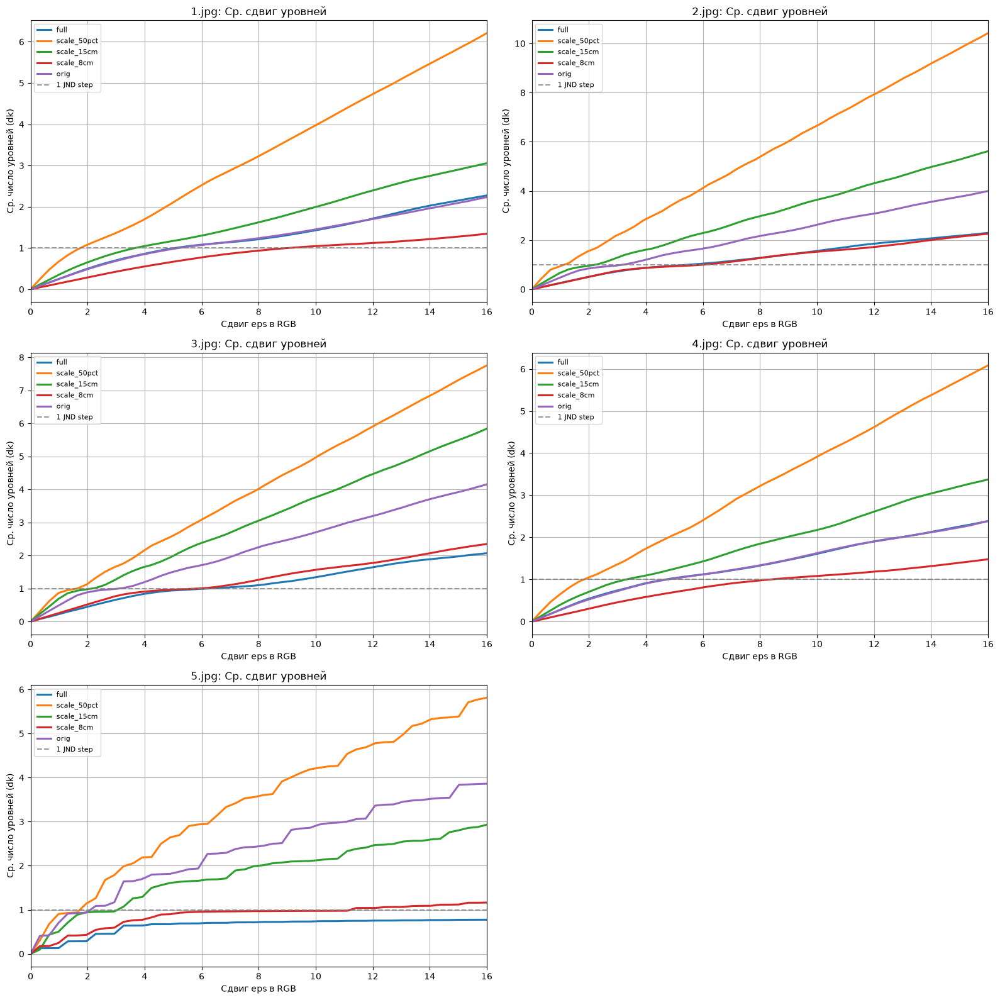

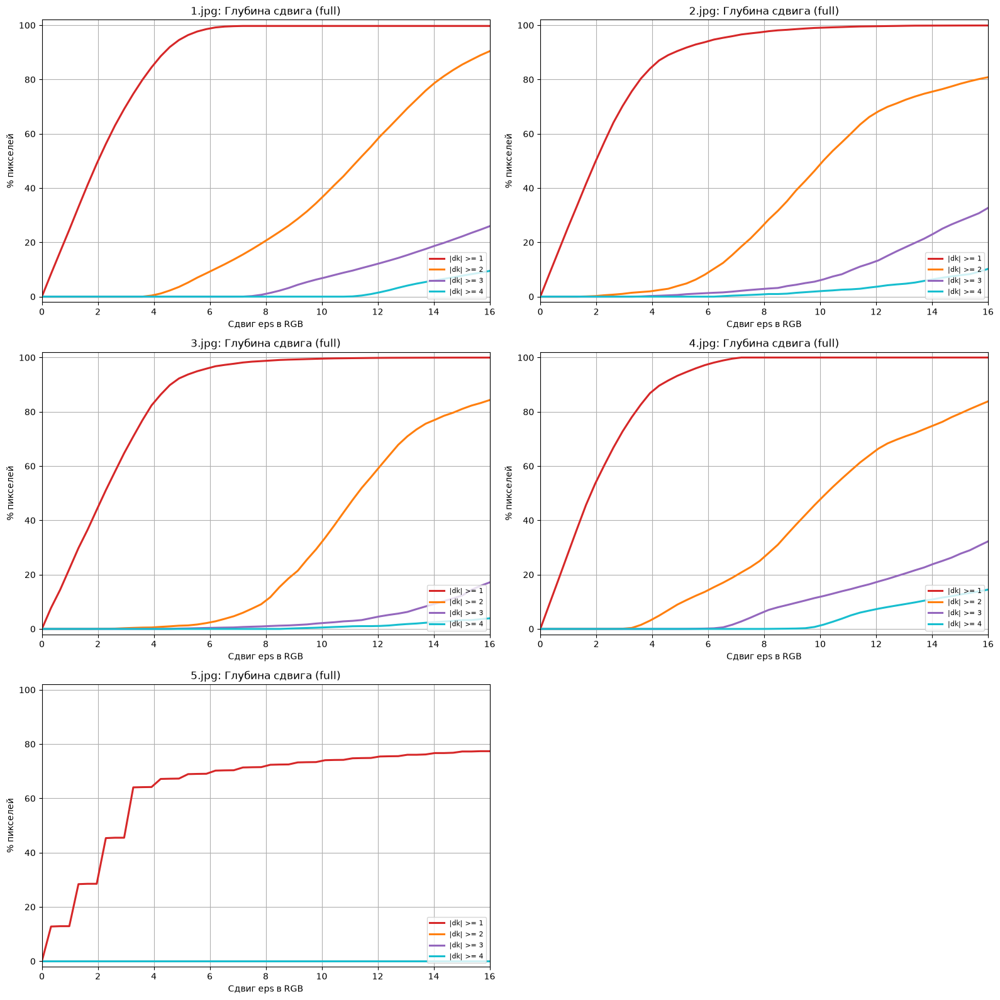

In [9]:
fig_ml, axes_ml = plt.subplots(3, 2, figsize=(16, 16))
axes_ml = axes_ml.ravel()
axes_ml[5].axis('off')

for img_idx, img_path in enumerate(image_paths):
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    l_physical = converter.RGB_to_xyzL(img_rgb)[..., 3]
    pixel_val = to_pixel_scale(l_physical)
    img_name = os.path.basename(img_path)

    eps_grid = np.linspace(0, 16.0, 50)
    for mode in modes:
        phi, n_total, n_patch, n_bg = compute_screen_geometry(l_physical.shape, mode=mode, distance_m=0.5)
        model = HistogramAdaptationJNDModel(angular_size_rad=phi, l_gray=60.0)
        la = model.find_la(l_physical, n_total, n_patch, n_bg, l_bg=60.0)
        bounds = model.build_level_boundaries()

        k_orig = np.searchsorted(bounds, l_physical, side='right') - 1
        k_orig = np.clip(k_orig, 0, len(bounds) - 2)
        lower_px = to_pixel_scale(bounds[k_orig])
        upper_px = to_pixel_scale(bounds[k_orig + 1])
        dist_down = pixel_val - lower_px
        dist_up = upper_px - pixel_val
        direction = np.where(dist_down <= dist_up, -1.0, 1.0)

        mean_shifts = []
        for eps in eps_grid:
            pert_px = np.clip(pixel_val + direction * eps, 0.0, 255.0)
            pert_L = to_phys_scale(pert_px)
            k_pert = np.searchsorted(bounds, pert_L, side='right') - 1
            k_pert = np.clip(k_pert, 0, len(bounds) - 2)
            delta_k = np.abs(k_pert - k_orig)
            mean_shifts.append(float(np.mean(delta_k)))

        axes_ml[img_idx].plot(
            eps_grid, mean_shifts,
            label=f"{mode}",
            color=mode_colors[mode],
            linewidth=2.2
        )

    axes_ml[img_idx].axhline(1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.8, label='1 JND step')
    axes_ml[img_idx].set_title(f"{img_name}: Ср. сдвиг уровней", fontsize=12)
    axes_ml[img_idx].set_xlabel("Сдвиг eps в RGB", fontsize=10)
    axes_ml[img_idx].set_ylabel("Ср. число уровней (dk)", fontsize=10)
    axes_ml[img_idx].set_xlim(0, 16.0)
    axes_ml[img_idx].grid(True)
    axes_ml[img_idx].legend(loc='upper left', fontsize=8)

plt.tight_layout()
plt.show()

fig_dist, axes_dist = plt.subplots(3, 2, figsize=(16, 16))
axes_dist = axes_dist.ravel()
axes_dist[5].axis('off')

for img_idx, img_path in enumerate(image_paths):
    img_bgr = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    l_physical = converter.RGB_to_xyzL(img_rgb)[..., 3]
    pixel_val = to_pixel_scale(l_physical)
    img_name = os.path.basename(img_path)

    phi, n_total, n_patch, n_bg = compute_screen_geometry(l_physical.shape, mode='full', distance_m=0.5)
    model = HistogramAdaptationJNDModel(angular_size_rad=phi, l_gray=60.0)
    la = model.find_la(l_physical, n_total, n_patch, n_bg)
    bounds = model.build_level_boundaries()

    k_orig = np.searchsorted(bounds, l_physical, side='right') - 1
    k_orig = np.clip(k_orig, 0, len(bounds) - 2)
    lower_px = to_pixel_scale(bounds[k_orig])
    upper_px = to_pixel_scale(bounds[k_orig + 1])
    dist_down = pixel_val - lower_px
    dist_up = upper_px - pixel_val
    direction = np.where(dist_down <= dist_up, -1.0, 1.0)

    eps_grid = np.linspace(0, 16.0, 50)
    pct_1, pct_2, pct_3, pct_4 = [], [], [], []
    for eps in eps_grid:
        pert_px = np.clip(pixel_val + direction * eps, 0.0, 255.0)
        pert_L = to_phys_scale(pert_px)
        k_pert = np.searchsorted(bounds, pert_L, side='right') - 1
        k_pert = np.clip(k_pert, 0, len(bounds) - 2)
        delta_k = np.abs(k_pert - k_orig)

        pct_1.append(float(np.mean(delta_k >= 1) * 100))
        pct_2.append(float(np.mean(delta_k >= 2) * 100))
        pct_3.append(float(np.mean(delta_k >= 3) * 100))
        pct_4.append(float(np.mean(delta_k >= 4) * 100))

    axes_dist[img_idx].plot(eps_grid, pct_1, color='#d62728', linewidth=2.2, label='|dk| >= 1')
    axes_dist[img_idx].plot(eps_grid, pct_2, color='#ff7f0e', linewidth=2.2, label='|dk| >= 2')
    axes_dist[img_idx].plot(eps_grid, pct_3, color='#9467bd', linewidth=2.2, label='|dk| >= 3')
    axes_dist[img_idx].plot(eps_grid, pct_4, color='#17becf', linewidth=2.2, label='|dk| >= 4')
    axes_dist[img_idx].set_title(f"{img_name}: Глубина сдвига (full)", fontsize=12)
    axes_dist[img_idx].set_xlabel("Сдвиг eps в RGB", fontsize=10)
    axes_dist[img_idx].set_ylabel("% пикселей", fontsize=10)
    axes_dist[img_idx].set_xlim(0, 16.0)
    axes_dist[img_idx].set_ylim(-2, 102)
    axes_dist[img_idx].grid(True)
    axes_dist[img_idx].legend(loc='lower right', fontsize=8)

plt.tight_layout()
plt.show()

## Блок 5. Синтетический бимодальный тест

### Что тестируем
Синтетическое изображение из двух яркостей: 30 кд/м² и 180 кд/м² при соотношениях 50/50, 55/45, 45/55, 70/30, 30/70.

### Что проверяем
Скачок адаптации La и минимальную ширину ступени (Simkin score) при смене доминирующей моды.

### Параметры эксперимента
* Размер синтетического патча: 100x100 пикселей
* Проверяемые яркости: L1 = 30 кд/м², L2 = 180 кд/м²
* Экран: 16 дюймов, расстояние 0.5 м

In [10]:
experiments = [
    (0.50, 0.50, "50% 30 / 50% 180"),
    (0.55, 0.45, "55% 30 / 45% 180"),
    (0.45, 0.55, "45% 30 / 55% 180"),
    (0.70, 0.30, "70% 30 / 30% 180"),
    (0.30, 0.70, "30% 30 / 70% 180")
]

h_px, w_px = 100, 100
total_px = h_px * w_px
synth_results = []
phi_synth = 0.0003689

for p1, p2, label in experiments:
    n1 = int(round(total_px * p1))
    n2 = total_px - n1
    patch = np.array([30.0] * n1 + [180.0] * n2, dtype=np.float64).reshape(h_px, w_px)
    mean_L = 30.0 * p1 + 180.0 * p2

    model_synth = HistogramAdaptationJNDModel(angular_size_rad=phi_synth, l_gray=60.0)
    L_hist = np.array([30.0, 180.0])
    p_hist = np.array([p1, p2])
    res = model_synth.fit(L_hist, p_hist)
    model_synth.la = res.La
    bounds = model_synth.build_level_boundaries()
    metrics = compute_jnd_step_metrics(patch, bounds, converter, has_bg=False)

    synth_results.append({
        "distribution": label,
        "mean_L": mean_L,
        "La": model_synth.la,
        **metrics
    })

df_synth = pd.DataFrame(synth_results)
display(df_synth[["distribution", "mean_L", "La", "num_levels", "min_delta_to_level_change", "min_jnd_step", "mean_delta_L1", "mean_jnd_step"]])


,distribution,mean_L,La,num_levels,min_delta_to_level_change,min_jnd_step,mean_delta_L1,mean_jnd_step
0,50% 30 / 50% 180,105.0000,179.9999,15,0.0001,6.1078,0.3176,8.5387
1,55% 30 / 45% 180,97.5000,30.0000,13,0.0000,6.7220,0.2887,10.0990
2,45% 30 / 55% 180,112.5000,179.9999,15,0.0001,6.1078,0.2858,8.7818
3,70% 30 / 30% 180,75.0000,30.0000,13,0.0000,6.7220,0.1925,8.9733
4,30% 30 / 70% 180,135.0000,179.9999,15,0.0001,6.1078,0.1906,9.5111
